# 02 · Comparing recommendation models

Every model is trained on each user's **past** ratings and asked to predict the movies the user
**later liked** (rating ≥ 4). Same split, same metrics, same code for all models
(`backend/app/recsys/evaluate.py`).

| metric | meaning |
|---|---|
| precision@10 | share of the 10 picks the user really went on to like |
| recall@10 | share of the user's later likes that appear in the 10 picks |
| ndcg@10 | like recall, but a hit at rank 1 counts more than a hit at rank 10 |
| coverage | share of the catalog that gets recommended to anyone |
| diversity | how different the genres within one list are (0 = all same) |

In [1]:
import sys
sys.path.insert(0, "../backend")

import matplotlib.pyplot as plt
from app.recsys.compare import main

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
results = main()

train=80,706 ratings  test=9,352 liked  users=589


{'model': 'popularity', 'precision@10': 0.0604, 'recall@10': 0.05, 'ndcg@10': 0.0786, 'coverage': 0.0092, 'diversity': 0.7755, 'fit_seconds': 0.0, 'users': 589}


{'model': 'tfidf', 'precision@10': 0.009, 'recall@10': 0.0092, 'ndcg@10': 0.0115, 'coverage': 0.1114, 'diversity': 0.1934, 'fit_seconds': 0.1, 'users': 589}


{'model': 'embedding (all-MiniLM-L6-v2)', 'precision@10': 0.0042, 'recall@10': 0.0047, 'ndcg@10': 0.0058, 'coverage': 0.0631, 'diversity': 0.6422, 'fit_seconds': 0.1, 'users': 589}


{'model': 'embedding (all-mpnet-base-v2)', 'precision@10': 0.0097, 'recall@10': 0.0102, 'ndcg@10': 0.0125, 'coverage': 0.0645, 'diversity': 0.669, 'fit_seconds': 0.1, 'users': 589}


{'model': 'tfidf + pop (w=1.0)', 'precision@10': 0.0294, 'recall@10': 0.0233, 'ndcg@10': 0.036, 'coverage': 0.0363, 'diversity': 0.4408, 'fit_seconds': 0.1, 'users': 589}


... (4 outputs left out)

/home/mg/Development/WIN-recommender-system/backend/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/mg/Development/WIN-recommender-system/backend/.venv/lib/python3.12/site-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


{'model': 'als (f=32, reg=0.05, a=10)', 'precision@10': 0.0813, 'recall@10': 0.0862, 'ndcg@10': 0.1024, 'coverage': 0.0736, 'diversity': 0.786, 'fit_seconds': 1.2, 'users': 589}


{'model': 'als (f=64, reg=0.05, a=10)', 'precision@10': 0.0728, 'recall@10': 0.0867, 'ndcg@10': 0.0983, 'coverage': 0.0796, 'diversity': 0.7975, 'fit_seconds': 2.0, 'users': 589}


{'model': 'als (f=128, reg=0.1, a=20)', 'precision@10': 0.062, 'recall@10': 0.0788, 'ndcg@10': 0.0816, 'coverage': 0.1051, 'diversity': 0.8041, 'fit_seconds': 2.8, 'users': 589}
                                      model  precision@10  recall@10  ndcg@10  coverage  diversity  fit_seconds  users
                 als (f=32, reg=0.05, a=10)      0.081324   0.086206 0.102358  0.073599   0.786023          1.2    589
                 als (f=64, reg=0.05, a=10)      0.072835   0.086658 0.098305  0.079552   0.797505          2.0    589
 embedding (all-MiniLM-L6-v2) + pop (w=1.0)      0.066723   0.062811 0.082369  0.012113   0.806478          0.1    589
                 als (f=128, reg=0.1, a=20)      0.061969   0.078779 0.081638  0.105112   0.804119          2.8    589
embedding (all-mpnet-base-v2) + pop (w=2.0)      0.063497   0.057163 0.079453  0.009546   0.805521          0.1    589
                                 popularity      0.060441   0.050047 0.078560  0.009238   0.775519          

In [2]:
results.round(4)

,model,precision@10,recall@10,ndcg@10,coverage,diversity,fit_seconds,users
9,"als (f=32, reg=0.05, a=10)",0.0813,0.0862,0.1024,0.0736,0.7860,1.2,589
10,"als (f=64, reg=0.05, a=10)",0.0728,0.0867,0.0983,0.0796,0.7975,2.0,589
5,embedding (all-MiniLM-L6-v2) + pop (w=1.0),0.0667,0.0628,0.0824,0.0121,0.8065,0.1,589
11,"als (f=128, reg=0.1, a=20)",0.0620,0.0788,0.0816,0.1051,0.8041,2.8,589
8,embedding (all-mpnet-base-v2) + pop (w=2.0),0.0635,0.0572,0.0795,0.0095,0.8055,0.1,589
0,popularity,0.0604,0.0500,0.0786,0.0092,0.7755,0.0,589
7,embedding (all-mpnet-base-v2) + pop (w=1.0),0.0567,0.0522,0.0681,0.0121,0.7893,0.1,589
6,embedding (all-mpnet-base-v2) + pop (w=0.5),0.0421,0.0390,0.0522,0.0187,0.7519,0.1,589
4,tfidf + pop (w=1.0),0.0294,0.0233,0.0360,0.0363,0.4408,0.1,589
3,embedding (all-mpnet-base-v2),0.0097,0.0102,0.0125,0.0645,0.6690,0.1,589


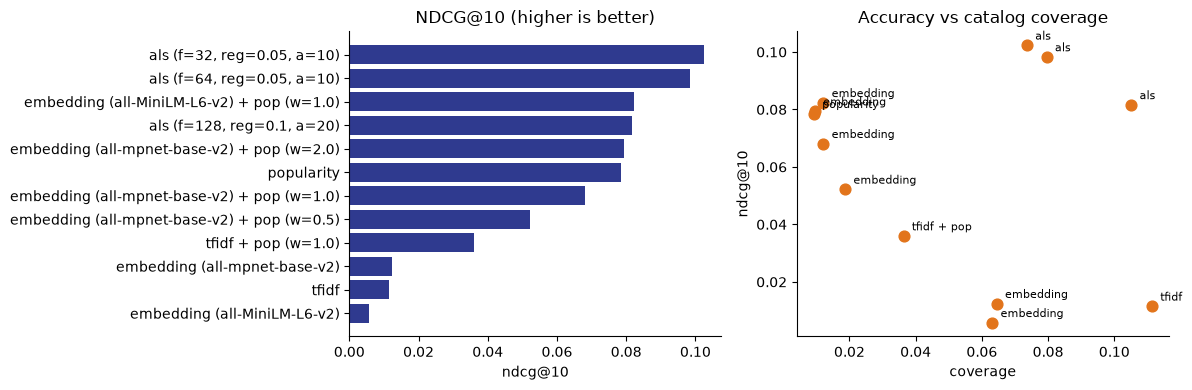

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
r = results.sort_values("ndcg@10")
a.barh(r["model"], r["ndcg@10"], color="#2f3a8f")
a.set(title="NDCG@10 (higher is better)", xlabel="ndcg@10")
b.scatter(results["coverage"], results["ndcg@10"], color="#e2741b", s=60)
for _, row in results.iterrows():
    b.annotate(row["model"].split(" (")[0], (row["coverage"], row["ndcg@10"]),
               textcoords="offset points", xytext=(6, 4), fontsize=8)
b.set(title="Accuracy vs catalog coverage", xlabel="coverage", ylabel="ndcg@10")
plt.tight_layout()

## Decision

| model | ndcg@10 | vs popularity |
|---|---|---|
| ALS (collaborative filtering, 32 factors) | **0.102** | +30% |
| MiniLM embeddings + popularity prior | **0.082** | +5% |
| popularity baseline | 0.079 | – |
| mpnet embeddings alone | 0.012 | −84% |
| TF-IDF alone | 0.012 | −85% |

**What we learned**
1. **Collaborative filtering wins on MovieLens.** That's expected: 610 users rating overlapping popular movies is exactly what ALS needs.
2. **Pure content models lose badly** (even below popularity). They follow taste but ignore that people mostly watch well-known titles, so they recommend obscure movies, 35% of which only one person ever rated.
3. **A small popularity prior fixes most of it.** Content similarity + popularity goes from 0.006 to 0.082 (14×) and beats the baseline.
4. **The bigger embedding model didn't help.** mpnet is 5× slower to encode and not better once popularity is added. With only titles, genres and a few tags there isn't much text for it to use.

**Decision for WIN:** use **MiniLM embeddings + popularity prior** as the recommendation engine.
- ALS can't be used for WIN's core job. It needs users who rated items in *both* categories, and a new app has no users (the cold-start problem). Embeddings put a movie, a book and a game in the same vector space using only their descriptions.
- MiniLM is small (384 dimensions), fast on CPU, and matched the larger model here.
- The popularity weight is a knob: lower it for more discovery (coverage), raise it for safer picks.

**Next checks**
- Re-run this comparison once items have TMDB overviews and keywords (Phase 2). Content models should improve with real descriptions.
- Coverage is low (1.2%) at w=1.0. Watch it in the app and tune the weight.
- Once WIN collects its own 👍/👎 feedback, ALS can be added as a second signal within each category (Phase 3).